In [1]:
using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
# include("run_sim.jl")
include("run_simulation.jl")
include("conv_spikes.jl") 
# include("firing_rates_max.jl") 


conv_spikes (generic function with 1 method)

In [2]:
function run_sim_optim_constant_inh(MN_list,i,inh_input) #tuned for one motoneuron only #NATALIA OF THE FUTURE ADD SMALL NOISE !!!!!!
    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    # _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end

function conv_spikes_rates(array1,array2)
    window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
    hanning_window = DSP.Windows.hanning(window_samples);
    hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

    smoothed_spike_array1 = conv(array1[1,:], hanning_window)/(1/20000)
    smoothed_spike_array2 = conv(array2[1,:], hanning_window)/(1/20000)

    # Because convolution extends the length of the array, let's truncate it to the original length
    len = size(array1,2);
    smoothed_spike_array1 = smoothed_spike_array1[1:len];
    smoothed_spike_array2 = smoothed_spike_array2[1:len];
    print("")

return smoothed_spike_array1, smoothed_spike_array2
end
   

conv_spikes_rates (generic function with 1 method)

In [4]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87

JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/VthCaVL_gamma07_28Jul.jld2" VthCa_newVL


# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 

Vthca_S = VthCa_newVL
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
sim_length=5000
frequency = 0.7     # Frequency in Hz
amplitude_min = 0.16
amplitude_max = 0.3
duration = 5      # Duration in seconds

# Time array
t = range(0, stop=duration, length=sim_length)

# Generate the sinusoidal signal with a frequency of 3 Hz
x_values = 2 * π * frequency * t
signal = sin.(x_values .- π/2)  # Adjust phase to start at minimum

# Scale the signal to range from 0.16 to 0.4
signal = (signal .+ 1) / 2  # Normalize to range [0, 1]
tr = signal * (amplitude_max - amplitude_min) .+ amplitude_min  # Scale to range [0.16, 0.4]


# at some point delete these things
γa=1.;
γh = ones(nr_s)*0.7#γn_new
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 

ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;


tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage

commoninput = tr; #needed for the run_sim() function


full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0.1 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length);


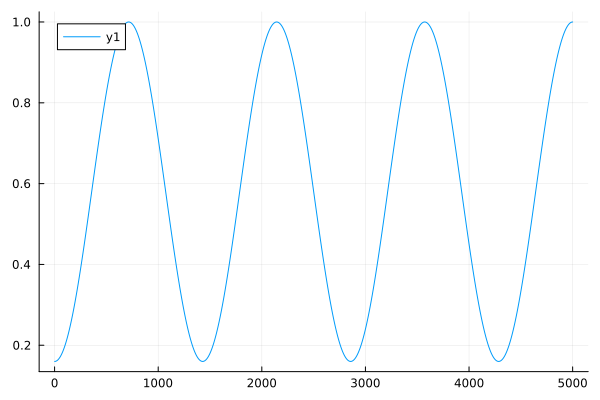

In [99]:


# x_values = range(0, stop=frequency*2π, length=sim_length)
# tr = (amplitude / 2) * sin.(x_values .- π/2) .+ (amplitude / 2)
sim_length=5000
frequency = 0.7     # Frequency in Hz
amplitude_min = 0.16
amplitude_max = 1
duration = 5      # Duration in seconds

# Time array
t = range(0, stop=duration, length=sim_length)

# Generate the sinusoidal signal with a frequency of 3 Hz
x_values = 2 * π * frequency * t
signal = sin.(x_values .- π/2)  # Adjust phase to start at minimum

# Scale the signal to range from 0.16 to 0.4
signal = (signal .+ 1) / 2  # Normalize to range [0, 1]
ideal_force = signal * (amplitude_max - amplitude_min) .+ amplitude_min  # Scale to range [0.16, 0.4]

Plots.plot(ideal_force)

In [175]:
###################### EXC ###################### (just controlling exc)
#################################################

# Control parameters
kp = Float32(4)  
kd = Float32(0.1)  
dt = Float32(0.1) 
ki= Float32(0.05) 
# Motoneurons we are interested in comparing
mn1 = 49
mn2 = 55

integral_error= 0.0

# Init
previous_error= 0.0

tr_new = copy(tr)
inh_input=fill(0.1*amplitude, sim_length);


for  iteration in 1:20

    commoninput = tr_new  

    # Run simulation for the 2 MNs we are comparing
    global spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1, inh_input) 
    global spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2, inh_input)  


    spike_array= vcat(spike_arr_mn1,spike_arr_mn2)
    Apeak_S = LinRange(0.103,0.123,nr_s)
    tpeak_S = LinRange(110.,100.,nr_s) 
    tetanic_S = LinRange(0.393,0.491,nr_s);

    Apeak_S= [Apeak_S[mn1], Apeak_S[mn2]]
    tpeak_S= [tpeak_S[mn1], tpeak_S[mn2]]
    tetanic_S= [tetanic_S[mn1], tetanic_S[mn2]]

    T=0.05
    twforce = zeros(size(spike_array))

    for i in 1:size(spike_array, 1)
        firings = copy(spike_array) /0.05

        # filter coefficients
        a = [1, -2 * exp(-T / tpeak_S[i]), exp(-2 * T / tpeak_S[i])]
        b = [0, Apeak_S[i] * (T^2 / tpeak_S[i]) * exp(1 - T / tpeak_S[i])]

        twforce[i, :] = filt(b, a, firings[i, :])

        # Tetanic Limit
        twforce[i, twforce[i, :] .> tetanic_S[i]] .= tetanic_S[i]
    end

    trajectory2_controlled = sum(twforce, dims=1)# Sum forces from both neurons


    v = 20
    n = div(size(trajectory2_controlled, 2), v)
    new_avg = zeros(n)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[1,start_idx:end_idx])
    end
    
    trajectory2_controlled = new_avg #avg every 20 points

    global trajectory2_controlled = new_avg #avg every 20 points
    
    global trajectory1 = ideal_force


   
    for i in 2:size(trajectory1, 1) 



        # computation of the euclidean error
        error = trajectory1[i] - trajectory2_controlled[i]



        # ERRORS FROM CONTROL OUTPUT
        
        integral_error += error * dt  
        derivative_error = (error - previous_error) / dt
        control_output = kp * error + kd * derivative_error #+ ki * integral_error 


        tr_new[i] += control_output/60

        tr_new[i] = clamp(tr_new[i], 0.0, 0.4)


        previous_error = error


    end

    
end

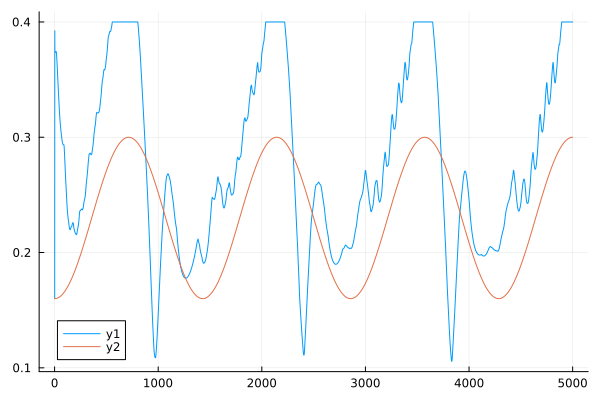

In [176]:
Plots.plot(tr_new)
Plots.plot!(tr)

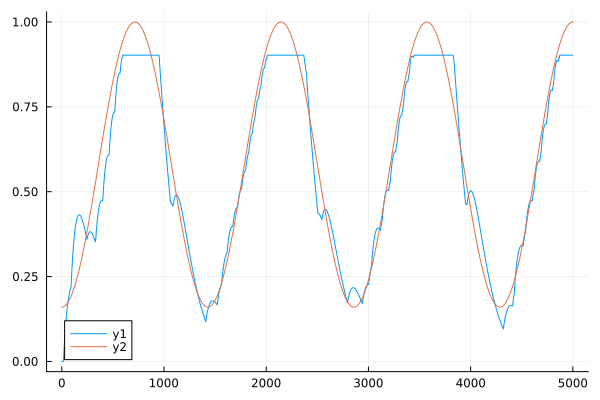

In [172]:
Plots.plot(trajectory2_controlled)
Plots.plot!(ideal_force)